Image: test_image.png | shape: (180, 240) | OpenCV: 5.0.0


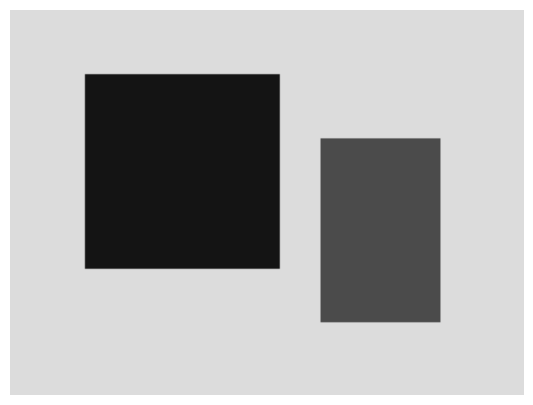

In [2]:
# Cell 1 — Select image already in Colab, or upload one
from google.colab import files
from pathlib import Path
import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd

IMAGE_PATH = 'test_image.png'  # e.g. '/content/photo.jpg'; leave blank to choose/upload
if not IMAGE_PATH:
    candidates = [p for p in Path('/content').iterdir()
                  if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')]
    if len(candidates) == 1:
        IMAGE_PATH = str(candidates[0])
    else:
        print('Upload your image:')
        uploaded = files.upload()
        IMAGE_PATH = '/content/' + next(iter(uploaded))

bgr = cv2.imread(IMAGE_PATH)
if bgr is None:
    raise ValueError(f'Could not read image: {IMAGE_PATH}')
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
print('Image:', IMAGE_PATH, '| shape:', gray.shape, '| OpenCV:', cv2.__version__)
plt.figure(figsize=(7,5)); plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

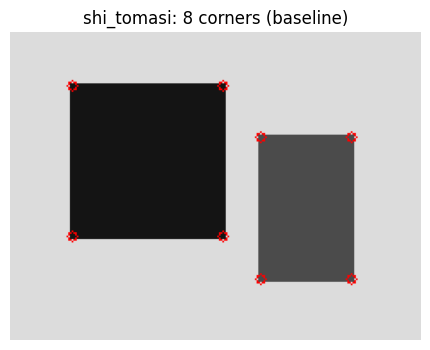

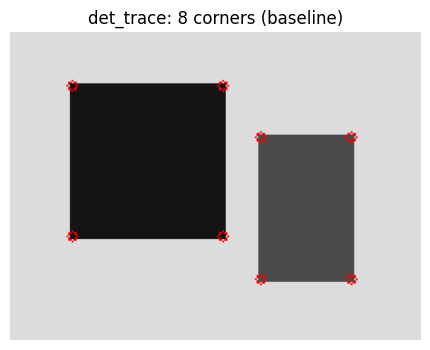

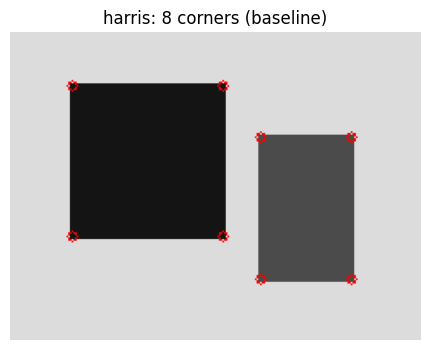

OpenCV version: 5.0.0 | EPS: 1e-12 | NMS: 3 x 3 | border policy: BORDER_DEFAULT


,experiment,detector,blockSize,ksize,alpha,corners,max_response,border_px
0,1,shi_tomasi,5,3,0.01,8,0.153787,4
1,1,det_trace,5,3,0.01,8,0.087500,4
2,1,harris,5,3,0.01,8,0.026127,4
3,2,shi_tomasi,3,3,0.01,8,0.153787,3
4,2,det_trace,3,3,0.01,8,0.100553,3
5,2,harris,3,3,0.01,8,0.036778,3
6,3,shi_tomasi,7,3,0.01,8,0.128679,5
7,3,det_trace,7,3,0.01,8,0.070059,5
8,3,harris,7,3,0.01,8,0.016598,5
9,4,shi_tomasi,5,5,0.01,8,1.231065,5


Results saved: /content/corner_results


In [3]:
# Cell 2 — Run controlled experiments and save all outputs
import csv
from pathlib import Path

OUTPUT = Path('/content/corner_results')
OUTPUT.mkdir(exist_ok=True)
EPS = 1e-12
NMS_SIZE = 3
K_HARRIS = 0.04

# Change these lists to explore one parameter at a time.
EXPERIMENTS = [
    {'blockSize': 5, 'ksize': 3, 'alpha': 0.01},  # baseline
    {'blockSize': 3, 'ksize': 3, 'alpha': 0.01},  # smaller integration window
    {'blockSize': 7, 'ksize': 3, 'alpha': 0.01},  # larger integration window
    {'blockSize': 5, 'ksize': 5, 'alpha': 0.01},  # larger derivative aperture
    {'blockSize': 5, 'ksize': 3, 'alpha': 0.03},  # stronger threshold
]


def select_corners(response, alpha, border):
    threshold_mask = np.zeros(response.shape, np.uint8)
    corner_mask = np.zeros(response.shape, np.uint8)
    max_val = float(np.max(response))
    if not np.isfinite(max_val) or max_val <= 0:
        return threshold_mask, corner_mask, np.empty((0, 2), np.int32)
    eligible = np.isfinite(response) & (response > alpha * max_val) & (response > 0)
    threshold_mask[eligible] = 255

    valid = np.zeros(response.shape, dtype=bool)
    if 2 * border < response.shape[0] and 2 * border < response.shape[1]:
        valid[border:-border, border:-border] = True
    maxima = cv2.dilate(response, np.ones((NMS_SIZE, NMS_SIZE), np.uint8))
    candidates = (eligible & valid & (response == maxima)).astype(np.uint8)

    # Equal-value 8-connected maxima plateau: retain lowest (y,x) only.
    count, labels = cv2.connectedComponents(candidates, connectivity=8)
    points = []
    for idx in range(1, count):
        ys, xs = np.where(labels == idx)
        y, x = int(ys[0]), int(xs[0])
        points.append([x, y])
        corner_mask[y, x] = 255
    return threshold_mask, corner_mask, np.asarray(points, np.int32).reshape(-1, 2)


summary = []
for exp_id, params in enumerate(EXPERIMENTS, 1):
    b = params['blockSize']; s = params['ksize']; alpha = params['alpha']
    assert b >= 3 and b % 2 == 1 and s in (3, 5, 7) and 0 < alpha < 1
    case = OUTPUT / f'exp_{exp_id:02d}_b{b}_s{s}_a{alpha:g}'
    case.mkdir(exist_ok=True)

    st = cv2.cornerMinEigenVal(gray, b, ksize=s, borderType=cv2.BORDER_DEFAULT)
    har = cv2.cornerHarris(gray, b, s, K_HARRIS, borderType=cv2.BORDER_DEFAULT)
    eigen = cv2.cornerEigenValsAndVecs(gray, b, ksize=s, borderType=cv2.BORDER_DEFAULT)
    la, lb = eigen[:, :, 0], eigen[:, :, 1]
    trace = la + lb
    dt = np.zeros_like(trace, dtype=np.float32)
    np.divide(la * lb, trace, out=dt, where=np.abs(trace) > EPS)

    border = s // 2 + b // 2 + NMS_SIZE // 2
    for name, response in [('shi_tomasi', st), ('det_trace', dt), ('harris', har)]:
        tmask, cmask, xy = select_corners(response, alpha, border)
        np.save(case / f'{name}_response.npy', response)
        np.save(case / f'{name}_threshold_mask.npy', tmask)
        np.save(case / f'{name}_corners_xy.npy', xy)
        np.savetxt(case / f'{name}_corners_xy.csv', xy, fmt='%d', delimiter=',',
                   header='x,y', comments='')
        heat = cv2.normalize(response, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
        cv2.imwrite(str(case / f'{name}_response.png'), heat)
        cv2.imwrite(str(case / f'{name}_threshold_mask.png'), tmask)
        cv2.imwrite(str(case / f'{name}_corner_mask.png'), cmask)
        overlay = bgr.copy()
        for x, y in xy:
            cv2.circle(overlay, (int(x), int(y)), 3, (0, 0, 255), 1)
        cv2.imwrite(str(case / f'{name}_overlay.png'), overlay)
        summary.append({'experiment': exp_id, 'detector': name, 'blockSize': b,
                        'ksize': s, 'alpha': alpha, 'corners': len(xy),
                        'max_response': float(response.max()), 'border_px': border})
        if exp_id == 1:
            plt.figure(figsize=(6, 4))
            plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
            plt.title(f'{name}: {len(xy)} corners (baseline)')
            plt.axis('off')
            plt.show()

summary_df = pd.DataFrame(summary)
summary_df.to_csv(OUTPUT / 'experiment_summary.csv', index=False)
print('OpenCV version:', cv2.__version__, '| EPS:', EPS,
      '| NMS:', NMS_SIZE, 'x', NMS_SIZE, '| border policy: BORDER_DEFAULT')
display(summary_df)
print('Results saved:', OUTPUT)

In [4]:
# Cell 3 — Download all outputs as one ZIP file
import shutil
from google.colab import files
zip_path = shutil.make_archive('/content/corner_results', 'zip', '/content/corner_results')
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>